In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("../data/processed/final/churn_model_data.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (6260, 73)


,customer_id,age,gender,country,city,acquisition_channel,customer_segment,preferred_language,tenure_days,total_viewing_sessions,...,customer_engagement_score,total_subscriptions_started,previously_ended_subscription_count,unique_plans_used_asof,has_used_multiple_plans_asof,current_plan_id_asof,monthly_price_asof,subscription_tenure_days_asof,churned,days_since_last_payment
0,CUST000744,21,Female,United Kingdom,Liverpool,Organic Search,Individual,English,2554,4.0,...,16.06,1,0,1,0,PLAN03,22.99,2554,False,2134
1,CUST001502,31,Male,Canada,Montreal,Referral,Family,French,138,5.0,...,33.62,1,0,1,0,PLAN01,6.99,138,False,18
2,CUST005383,40,Male,United Kingdom,Leeds,Paid Social,Student,English,1079,6.0,...,29.86,1,0,1,0,PLAN01,6.99,1079,False,659
3,CUST005877,36,Male,Indonesia,Jakarta,Email Campaign,Student,French,179,5.0,...,29.83,1,0,1,0,PLAN03,22.99,179,False,29
4,CUST003762,29,Male,Poland,Warsaw,App Store,Student,English,231,10.0,...,81.60,1,0,1,0,PLAN02,15.49,231,False,21


In [4]:
print("Column Names:")
for column in df.columns:
    print(column)

Column Names:
customer_id
age
gender
country
city
acquisition_channel
customer_segment
preferred_language
tenure_days
total_viewing_sessions
total_watch_duration_minutes
average_watch_duration_minutes
average_completion_percentage
average_session_duration_minutes
unique_content_watched
active_viewing_days
days_since_last_viewing
has_viewing_activity
total_support_tickets
unique_issue_categories
most_common_issue_category
has_support_activity
total_payment_transactions
successful_payment_count
failed_payment_count
total_amount_paid
average_successful_payment_amount
payment_success_rate
unique_payment_methods
most_used_payment_method
days_since_last_successful_payment
has_successful_payment
total_feedback_count
average_feedback_rating
positive_feedback_count
neutral_feedback_count
negative_feedback_count
negative_feedback_rate
latest_feedback_rating
latest_feedback_sentiment
days_since_last_feedback
has_feedback_activity
most_watched_genre
unique_genres_watched
most_watched_content_type


In [5]:
# Group columns by data type
numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Total Numeric Columns:", len(numeric_columns))
print("\nNumeric Columns:")
print(numeric_columns)

print("\nTotal Categorical Columns:", len(categorical_columns))
print("\nCategorical Columns:")
print(categorical_columns)

Total Numeric Columns: 57

Numeric Columns:
['age', 'tenure_days', 'total_viewing_sessions', 'total_watch_duration_minutes', 'average_watch_duration_minutes', 'average_completion_percentage', 'average_session_duration_minutes', 'unique_content_watched', 'active_viewing_days', 'days_since_last_viewing', 'has_viewing_activity', 'total_support_tickets', 'unique_issue_categories', 'has_support_activity', 'total_payment_transactions', 'successful_payment_count', 'failed_payment_count', 'total_amount_paid', 'average_successful_payment_amount', 'payment_success_rate', 'unique_payment_methods', 'days_since_last_successful_payment', 'has_successful_payment', 'total_feedback_count', 'average_feedback_rating', 'positive_feedback_count', 'neutral_feedback_count', 'negative_feedback_count', 'negative_feedback_rate', 'latest_feedback_rating', 'days_since_last_feedback', 'has_feedback_activity', 'unique_genres_watched', 'unique_content_types_watched', 'unique_languages_watched', 'unique_maturity_rati

C:\Users\USER\AppData\Local\Temp\ipykernel_13728\2202041244.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [6]:
# Step 5: Select segmentation features
segmentation_features = [
    "age",
    "tenure_days",
    "total_viewing_sessions",
    "total_watch_duration_minutes",
    "average_completion_percentage",
    "unique_content_watched",
    "active_viewing_days",
    "days_since_last_viewing",
    "payment_success_rate",
    "total_amount_paid",
    "monthly_price_asof",
    "subscription_tenure_days_asof",
    "days_since_last_payment",
    "total_support_tickets"
]

segmentation_df = df[segmentation_features].copy()

print("Selected Features:", len(segmentation_features))
print("Segmentation Dataset Shape:", segmentation_df.shape)

display(segmentation_df.head())

Selected Features: 14
Segmentation Dataset Shape: (6260, 14)


,age,tenure_days,total_viewing_sessions,total_watch_duration_minutes,average_completion_percentage,unique_content_watched,active_viewing_days,days_since_last_viewing,payment_success_rate,total_amount_paid,monthly_price_asof,subscription_tenure_days_asof,days_since_last_payment,total_support_tickets
0,21,2554,4.0,211.0,66.5,4.0,4.0,132.0,0.866667,298.87,22.99,2554,2134,0.0
1,31,138,5.0,309.0,72.8,5.0,5.0,31.0,1.000000,34.95,6.99,138,18,0.0
2,40,1079,6.0,301.0,76.5,6.0,6.0,122.0,0.933333,90.87,6.99,1079,659,0.0
3,36,179,5.0,286.0,60.8,5.0,5.0,46.0,0.833333,91.96,22.99,179,29,0.0
4,29,231,10.0,510.0,76.0,10.0,10.0,5.0,0.875000,108.43,15.49,231,21,0.0


In [7]:
# Step 6: Check missing values
missing_values = segmentation_df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(segmentation_df) * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
average_completion_percentage,42,0.67
days_since_last_viewing,42,0.67
tenure_days,0,0.00
total_viewing_sessions,0,0.00
total_watch_duration_minutes,0,0.00
age,0,0.00
unique_content_watched,0,0.00
active_viewing_days,0,0.00
payment_success_rate,0,0.00
total_amount_paid,0,0.00


In [8]:
# Step 7: Handle missing values
imputer = SimpleImputer(strategy="median")

segmentation_imputed = pd.DataFrame(
    imputer.fit_transform(segmentation_df),
    columns=segmentation_df.columns,
    index=segmentation_df.index
)

print("Missing values after imputation:")
print(segmentation_imputed.isnull().sum().sum())

print("Dataset Shape:", segmentation_imputed.shape)

Missing values after imputation:
0
Dataset Shape: (6260, 14)


In [9]:
# Step 8: Check feature distributions and outliers
display(segmentation_imputed.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,6260.0,32.542173,10.457393,5.00,25.000000,32.000000,39.000000,76.00
tenure_days,6260.0,1365.726358,777.850061,0.00,699.750000,1375.000000,2026.000000,2707.00
total_viewing_sessions,6260.0,7.205591,3.285927,0.00,5.000000,7.000000,9.000000,19.00
total_watch_duration_minutes,6260.0,355.043291,191.701099,0.00,227.000000,345.000000,457.250000,1730.00
average_completion_percentage,6260.0,70.391817,8.988287,10.00,65.333333,70.654762,75.833333,100.00
unique_content_watched,6260.0,7.153834,3.252805,0.00,5.000000,7.000000,9.000000,19.00
active_viewing_days,6260.0,7.083866,3.228997,0.00,5.000000,7.000000,9.000000,19.00
days_since_last_viewing,6260.0,43.557348,52.186309,0.00,8.000000,23.000000,61.000000,334.00
payment_success_rate,6260.0,0.939340,0.078059,0.00,0.933333,0.933333,1.000000,1.00
total_amount_paid,6260.0,181.044243,100.071905,0.00,97.860000,185.880000,232.350000,629.93


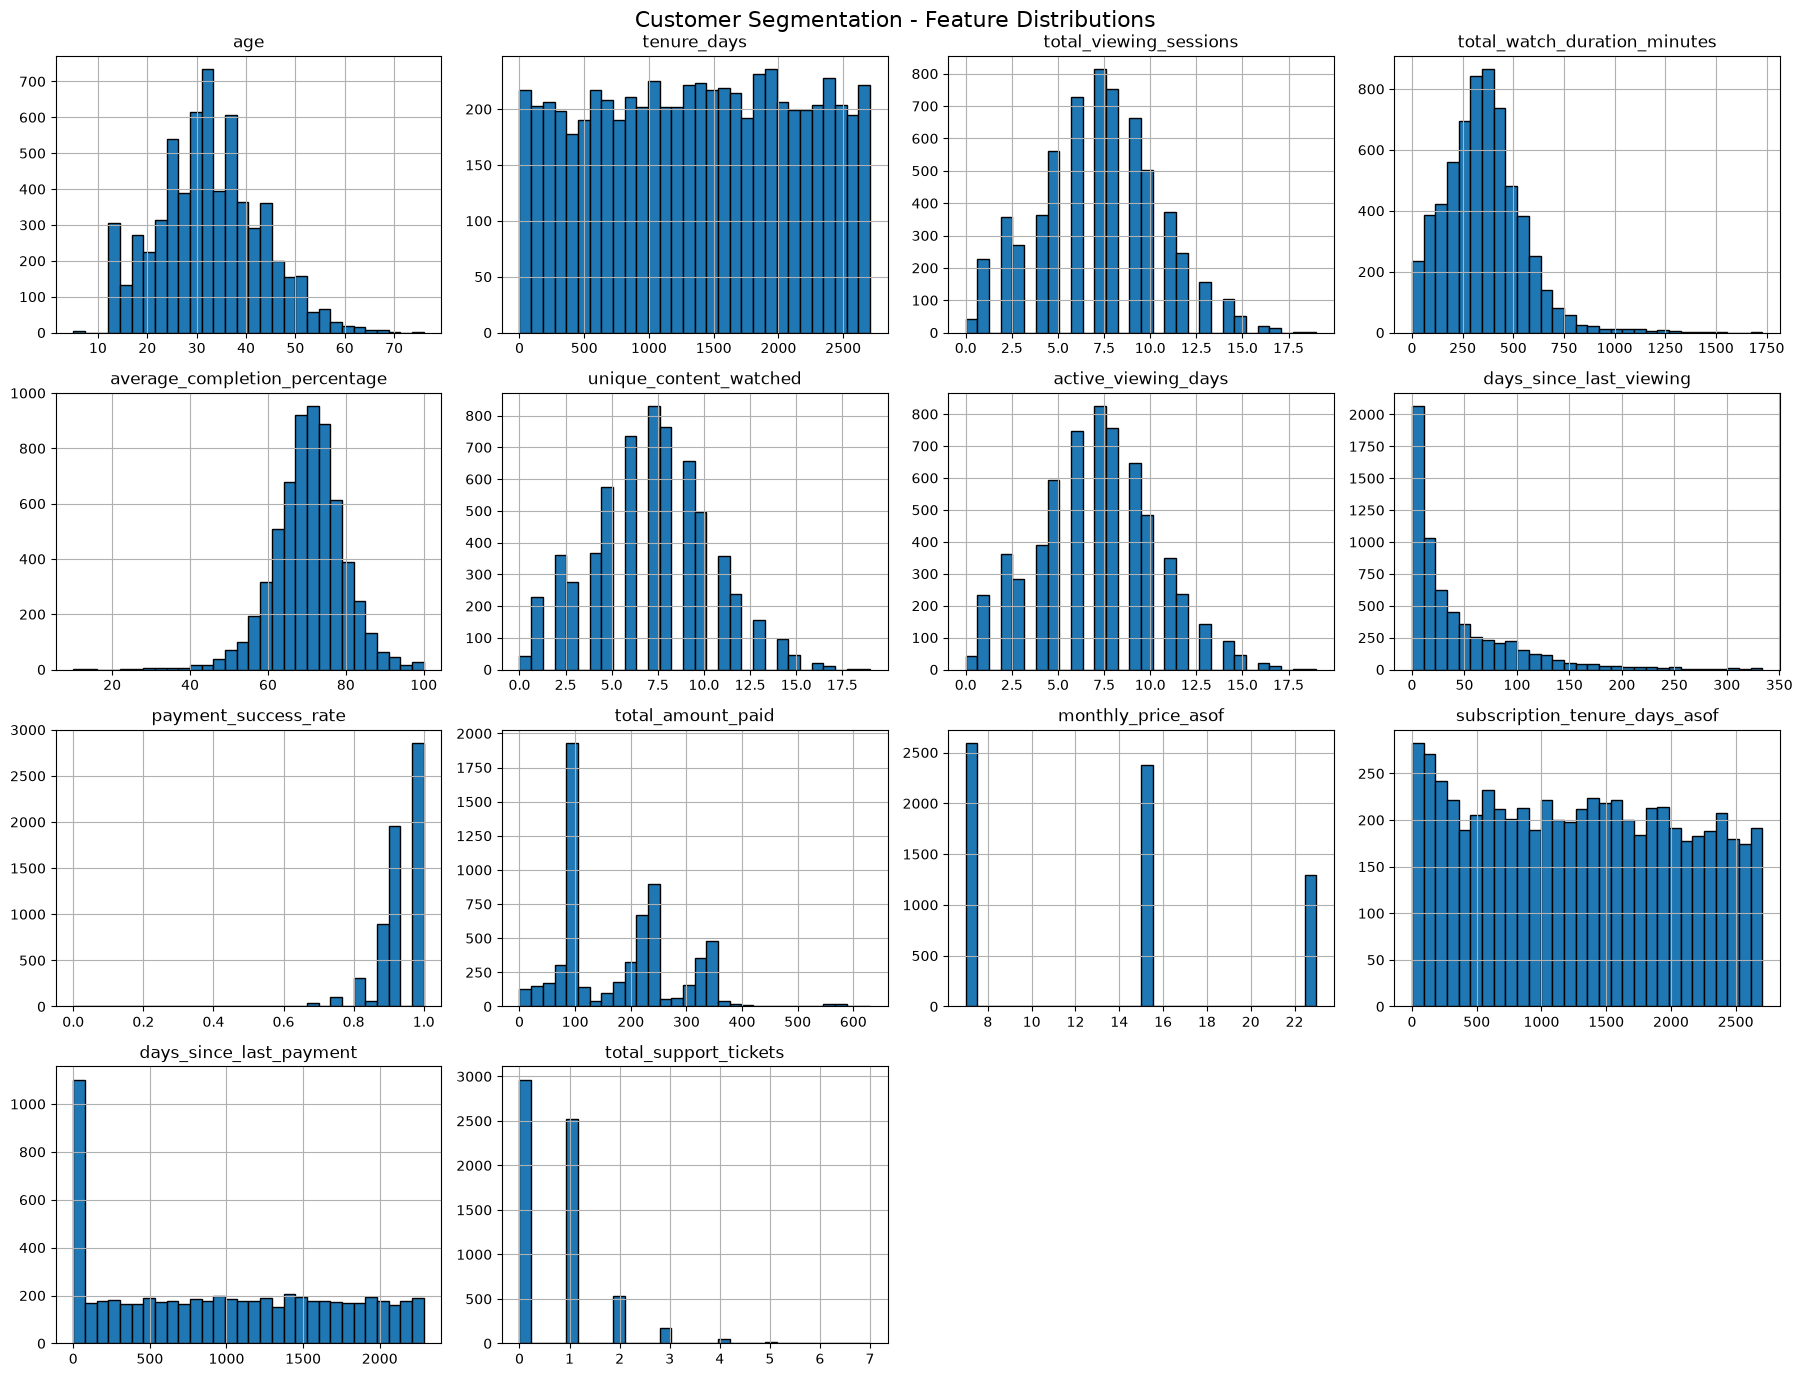

In [10]:
# Step 10: Visualize feature distributions
segmentation_imputed.hist(
    figsize=(18, 14),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Customer Segmentation - Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
# Step 11: Scale the features
scaler = StandardScaler()

segmentation_scaled = pd.DataFrame(
    scaler.fit_transform(segmentation_imputed),
    columns=segmentation_imputed.columns,
    index=segmentation_imputed.index
)

print("Scaled Dataset Shape:", segmentation_scaled.shape)
display(segmentation_scaled.head())

Scaled Dataset Shape: (6260, 14)


,age,tenure_days,total_viewing_sessions,total_watch_duration_minutes,average_completion_percentage,unique_content_watched,active_viewing_days,days_since_last_viewing,payment_success_rate,total_amount_paid,monthly_price_asof,subscription_tenure_days_asof,days_since_last_payment,total_support_tickets
0,-1.103821,1.527760,-0.975629,-0.751455,-0.433022,-0.969651,-0.955130,1.694884,-0.931074,1.177505,1.545289,1.601978,1.586175,-0.833996
1,-0.147484,-1.578485,-0.671277,-0.240202,0.267946,-0.662200,-0.645412,-0.240645,0.777169,-1.460009,-1.062587,-1.462582,-1.323288,-0.833996
2,0.713220,-0.368643,-0.366925,-0.281937,0.679626,-0.354748,-0.335693,1.503247,-0.076953,-0.901166,-1.062587,-0.268976,-0.441924,-0.833996
3,0.330685,-1.525771,-0.671277,-0.360190,-1.067231,-0.662200,-0.645412,0.046810,-1.358135,-0.890273,1.545289,-1.410576,-1.308163,-0.833996
4,-0.338751,-1.458915,0.850485,0.808389,0.623993,0.875058,0.903181,-0.738899,-0.824309,-0.725679,0.322847,-1.344617,-1.319163,-0.833996


In [12]:
# Step 12: Apply the Elbow Method
wcss = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(segmentation_scaled)
    wcss.append(kmeans.inertia_)

print("WCSS Values:", wcss)

WCSS Values: [72180.90699050725, 63141.41113060183, 58272.947565029404, 54635.38967654385, 51725.66420332569, 49248.671558488306, 47589.34177832154, 46040.95218521779, 44590.25593552209]


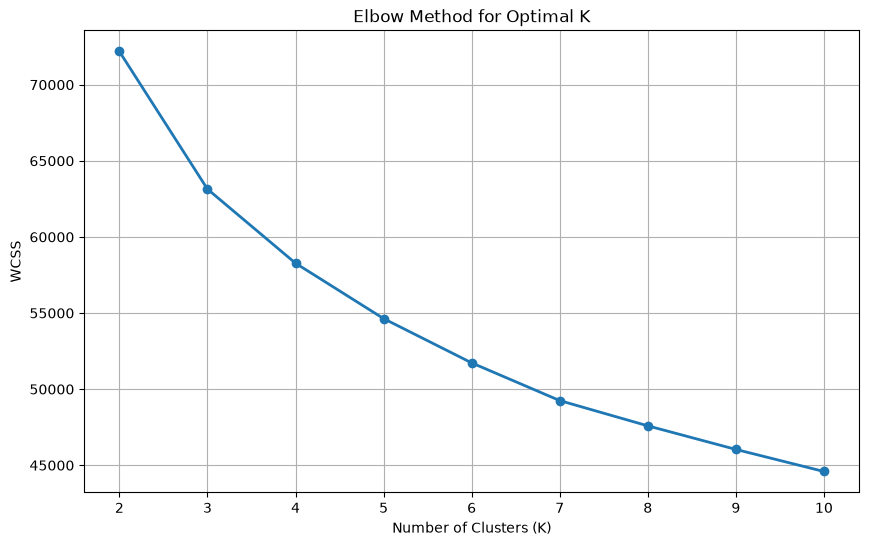

In [13]:
# Step 13: Plot the Elbow Curve
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    wcss,
    marker="o",
    linewidth=2
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [14]:
# Step 14: Calculate Silhouette Scores
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(segmentation_scaled)

    score = silhouette_score(segmentation_scaled, cluster_labels)

    silhouette_scores.append(score)

silhouette_results = pd.DataFrame({
    "Number of Clusters": range(2, 11),
    "Silhouette Score": silhouette_scores
})

display(silhouette_results)

,Number of Clusters,Silhouette Score
0,2,0.157346
1,3,0.150153
2,4,0.141924
3,5,0.135399
4,6,0.127955
5,7,0.124690
6,8,0.123518
7,9,0.119049
8,10,0.117218


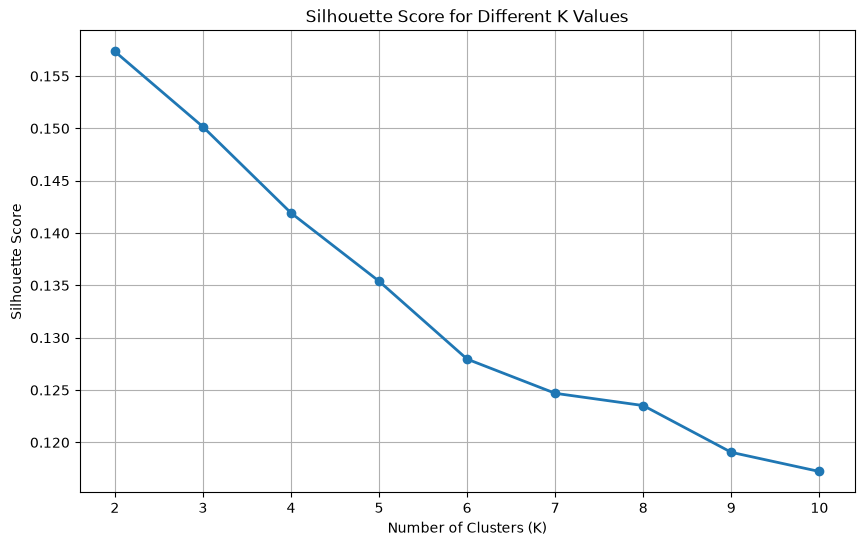

In [15]:
# Step 15: Visualize Silhouette Scores
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o",
    linewidth=2
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [16]:
# Step 16: Compare cluster sizes
cluster_comparison = []

for k in [2, 3, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(segmentation_scaled)

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    for cluster, size in cluster_sizes.items():
        cluster_comparison.append({
            "K": k,
            "Cluster": cluster,
            "Customers": size,
            "Percentage": round(size / len(df) * 100, 2)
        })

cluster_comparison_df = pd.DataFrame(cluster_comparison)

display(cluster_comparison_df)

,K,Cluster,Customers,Percentage
0,2,0,3085,49.28
1,2,1,3175,50.72
2,3,0,2048,32.72
3,3,1,2098,33.51
4,3,2,2114,33.77
5,4,0,988,15.78
6,4,1,1826,29.17
7,4,2,1424,22.75
8,4,3,2022,32.30


In [17]:
# Train the final K-Means model with K=3
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["cluster"] = final_kmeans.fit_predict(segmentation_scaled)

print("K-Means model trained successfully.")
print("\nCluster Distribution:")
print(df["cluster"].value_counts().sort_index())

print("\nSilhouette Score:",
      round(silhouette_score(segmentation_scaled, df["cluster"]), 4))

K-Means model trained successfully.

Cluster Distribution:
cluster
0    2048
1    2098
2    2114
Name: count, dtype: int64

Silhouette Score: 0.1502


In [18]:
# Step 18: Analyze cluster characteristics
cluster_profiles = df.groupby("cluster")[segmentation_features].mean().round(2)

display(cluster_profiles.T)

cluster,0,1,2
age,33.23,32.28,32.14
tenure_days,1405.35,2069.40,628.99
total_viewing_sessions,10.70,5.70,5.31
total_watch_duration_minutes,541.25,272.39,256.68
average_completion_percentage,70.60,70.30,70.28
unique_content_watched,10.61,5.67,5.29
active_viewing_days,10.51,5.62,5.22
days_since_last_viewing,32.44,52.85,45.57
payment_success_rate,0.93,0.94,0.94
total_amount_paid,190.50,203.75,149.36


In [19]:
# Step 19: Assign business-friendly labels
cluster_mapping = {
    0: "Highly Engaged Viewers",
    1: "Long-Term Subscribers",
    2: "Newer Low-Engagement Customers"
}

df["customer_cluster"] = df["cluster"].map(cluster_mapping)

print(df["customer_cluster"].value_counts())

display(
    df[["customer_id", "cluster", "customer_cluster"]].head(10)
)

customer_cluster
Newer Low-Engagement Customers    2114
Long-Term Subscribers             2098
Highly Engaged Viewers            2048
Name: count, dtype: int64


,customer_id,cluster,customer_cluster
0,CUST000744,1,Long-Term Subscribers
1,CUST001502,2,Newer Low-Engagement Customers
2,CUST005383,2,Newer Low-Engagement Customers
3,CUST005877,2,Newer Low-Engagement Customers
4,CUST003762,0,Highly Engaged Viewers
5,CUST007892,2,Newer Low-Engagement Customers
6,CUST002317,1,Long-Term Subscribers
7,CUST005609,0,Highly Engaged Viewers
8,CUST000519,0,Highly Engaged Viewers
9,CUST007084,1,Long-Term Subscribers


In [20]:
# Step 20: Analyze churn rate by customer segment
churn_analysis = df.groupby("customer_cluster").agg(
    total_customers=("customer_id", "count"),
    churned_customers=("churned", "sum")
)

churn_analysis["churn_rate"] = (
    churn_analysis["churned_customers"] /
    churn_analysis["total_customers"] * 100
).round(2)

display(churn_analysis.sort_values(
    by="churn_rate",
    ascending=False
))

,total_customers,churned_customers,churn_rate
customer_cluster,,,
Newer Low-Engagement Customers,2114,113,5.35
Highly Engaged Viewers,2048,73,3.56
Long-Term Subscribers,2098,65,3.10


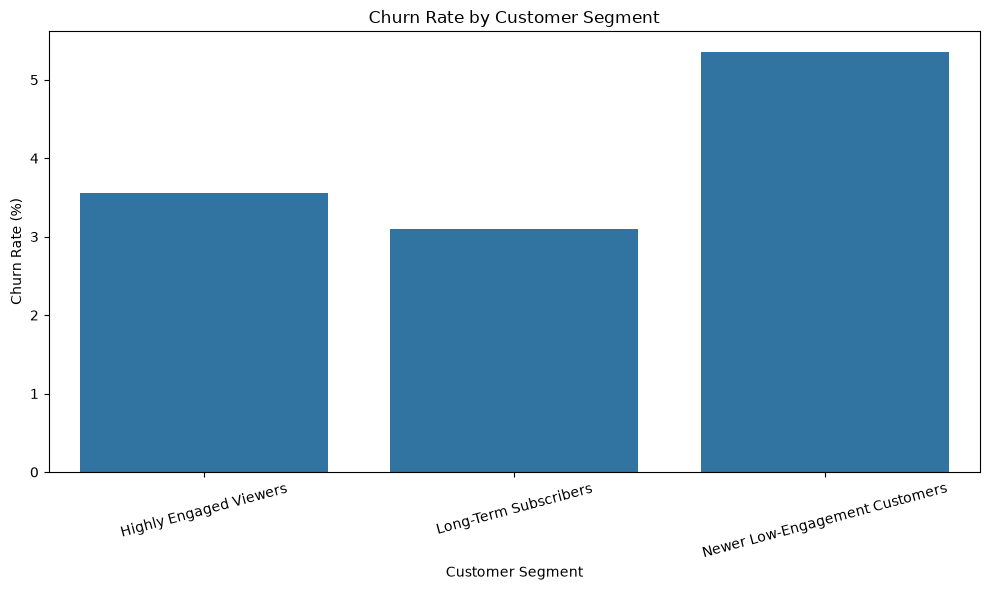

In [21]:
# Step 21: Visualize churn rates by segment
plt.figure(figsize=(10, 6))

sns.barplot(
    data=churn_analysis.reset_index(),
    x="customer_cluster",
    y="churn_rate"
)

plt.title("Churn Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [22]:
# Step 22: Analyze revenue contribution by segment
revenue_analysis = df.groupby("customer_cluster").agg(
    total_customers=("customer_id", "count"),
    total_revenue=("total_amount_paid", "sum"),
    average_revenue_per_customer=("total_amount_paid", "mean")
)

revenue_analysis["revenue_percentage"] = (
    revenue_analysis["total_revenue"] /
    revenue_analysis["total_revenue"].sum() * 100
).round(2)

revenue_analysis = revenue_analysis.round(2)

display(revenue_analysis.sort_values(
    by="total_revenue",
    ascending=False
))

,total_customers,total_revenue,average_revenue_per_customer,revenue_percentage
customer_cluster,,,,
Long-Term Subscribers,2098,427457.65,203.75,37.72
Highly Engaged Viewers,2048,390141.38,190.50,34.42
Newer Low-Engagement Customers,2114,315737.93,149.36,27.86


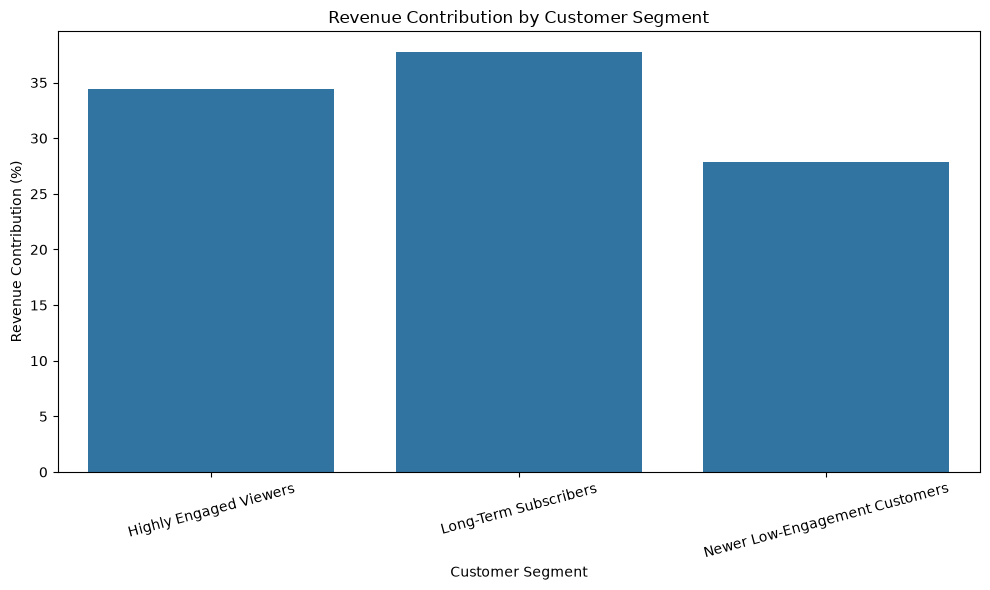

In [23]:
# Step 23: Visualize revenue contribution
plt.figure(figsize=(10, 6))

sns.barplot(
    data=revenue_analysis.reset_index(),
    x="customer_cluster",
    y="revenue_percentage"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [24]:
# Step 24: Viewing Behaviour Analysis
viewing_analysis = df.groupby("customer_cluster").agg(
    average_viewing_sessions=("total_viewing_sessions", "mean"),
    average_watch_duration=("total_watch_duration_minutes", "mean"),
    average_unique_content=("unique_content_watched", "mean"),
    average_active_days=("active_viewing_days", "mean")
).round(2)

display(viewing_analysis)

,average_viewing_sessions,average_watch_duration,average_unique_content,average_active_days
customer_cluster,,,,
Highly Engaged Viewers,10.70,541.25,10.61,10.51
Long-Term Subscribers,5.70,272.39,5.67,5.62
Newer Low-Engagement Customers,5.31,256.68,5.29,5.22


In [25]:
# Step 25 — Create a consolidated segmentation summary
segmentation_summary = churn_analysis.merge(
    revenue_analysis,
    on="customer_cluster",
    suffixes=("_churn", "_revenue")
).merge(
    viewing_analysis,
    on="customer_cluster"
)

display(segmentation_summary.round(2))

,total_customers_churn,churned_customers,churn_rate,total_customers_revenue,total_revenue,average_revenue_per_customer,revenue_percentage,average_viewing_sessions,average_watch_duration,average_unique_content,average_active_days
customer_cluster,,,,,,,,,,,
Highly Engaged Viewers,2048,73,3.56,2048,390141.38,190.50,34.42,10.70,541.25,10.61,10.51
Long-Term Subscribers,2098,65,3.10,2098,427457.65,203.75,37.72,5.70,272.39,5.67,5.62
Newer Low-Engagement Customers,2114,113,5.35,2114,315737.93,149.36,27.86,5.31,256.68,5.29,5.22


In [26]:
# Step 26 — Save the customer segmentation results
df[["customer_id", "cluster", "customer_cluster"]].to_csv(
    "../data/processed/final/customer_segments.csv",
    index=False
)

In [27]:
import os

file_path = "../data/processed/final/customer_segments.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
    display(pd.read_csv(file_path).head())

File exists: True
File size: 246472 bytes


,customer_id,cluster,customer_cluster
0,CUST000744,1,Long-Term Subscribers
1,CUST001502,2,Newer Low-Engagement Customers
2,CUST005383,2,Newer Low-Engagement Customers
3,CUST005877,2,Newer Low-Engagement Customers
4,CUST003762,0,Highly Engaged Viewers


In [29]:
# Create the models folder
import os

os.makedirs("../models", exist_ok=True)

print("Models folder created successfully")

Models folder created successfully


In [30]:
# Save the K-Means model
import joblib

joblib.dump(final_kmeans, "../models/customer_segmentation_kmeans.pkl")

print("K-Means model saved successfully")

K-Means model saved successfully


In [31]:
# Step 28 — Save the StandardScaler
joblib.dump(scaler, "../models/customer_segmentation_scaler.pkl")

print("Scaler saved successfully")

Scaler saved successfully


In [32]:
# Save the SimpleImputer
joblib.dump(imputer, "../models/customer_segmentation_imputer.pkl")

print("Imputer saved successfully")

Imputer saved successfully


In [33]:
# Step 30 — Verify all saved files
import os

model_files = [
    "customer_segmentation_kmeans.pkl",
    "customer_segmentation_scaler.pkl",
    "customer_segmentation_imputer.pkl"
]

for file in model_files:
    path = os.path.join("../models", file)
    print(f"{file}: {'Available' if os.path.exists(path) else 'Missing'}")

customer_segmentation_kmeans.pkl: Available
customer_segmentation_scaler.pkl: Available
customer_segmentation_imputer.pkl: Available


In [34]:
# Step 31 — Final segmentation business summary
print("CUSTOMER SEGMENTATION SUMMARY")
print("=" * 40)

for cluster_name in churn_analysis.index:
    print(f"\n{cluster_name}")
    print(f"Customers: {churn_analysis.loc[cluster_name, 'total_customers']}")
    print(f"Churn Rate: {churn_analysis.loc[cluster_name, 'churn_rate']}%")
    print(f"Revenue Contribution: {revenue_analysis.loc[cluster_name, 'revenue_percentage']}%")

CUSTOMER SEGMENTATION SUMMARY

Highly Engaged Viewers
Customers: 2048
Churn Rate: 3.56%
Revenue Contribution: 34.42%

Long-Term Subscribers
Customers: 2098
Churn Rate: 3.1%
Revenue Contribution: 37.72%

Newer Low-Engagement Customers
Customers: 2114
Churn Rate: 5.35%
Revenue Contribution: 27.86%
